# M5.4 · 过拟合诊断（PBO/CSCV、Deflated Sharpe）

> 回测漂亮往往是「在历史数据上反复试错、挑出最优」的结果。尝试的策略越多，纯靠运气得到高 Sharpe 的概率越大。
> 需要专门工具量化「回测过拟合概率」，并对选择偏差做校正。

## 一、核心方法

1. **CSCV / PBO（Bailey et al. 2014）**：组合对称交叉验证，把样本分块，训练集选最优策略，看其在验证集的排名；
   验证排名 logit $=\ln(\omega/(1-\omega))$，**PBO = logit<0 的频率**，即样本外落到下半区的概率；
2. **Deflated Sharpe（Bailey & López de Prado 2014）**：考虑试验次数 $N$ 的选择偏差，
$$SR_0=E[\max SR_N],\quad
DSR=\Phi\!\left(\frac{(SR_{obs}-SR_0)\sqrt{T-1}}
{\sqrt{1-\gamma_1 SR_{obs}+\frac{\gamma_2}{4}SR_{obs}^2}}\right)$$
3. **参数敏感性**：绩效在参数网格上的变异系数，越敏感越脆弱；
4. **置换检验 / bootstrap**：打乱信号得 p 值，重采样给 Sharpe 置信区间。

## 二、PBO 与 Deflated Sharpe

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np, pandas as pd
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from bt_lab2 import overfit as of
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$close'], start_time='2018-01-01', freq='day')
cl = raw['$close'].unstack('instrument')
ret = cl.pct_change(fill_method=None).iloc[-750:, :10].dropna(axis=1)
pbo = of.pbo_cscv(ret, n_blocks=6)
print('PBO=%.4f logit均值=%.3f 组合数=%d' % (pbo['PBO'], pbo['logit_mean'], pbo['n_combinations']))
srs = (ret.mean()/ret.std()).values; best = srs.max()
best_col = ret.columns[np.argmax(srs)]
dsr = of.deflated_sharpe(best, srs, len(ret), ret[best_col].skew(), ret[best_col].kurt())
print('DSR=%.4f 选择偏差基准SR0=%.4f' % (dsr['DSR'], dsr['benchmark_SR0']))

[24736:MainThread](2026-11-05 14:56:26,219) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[24736:MainThread](2026-11-05 14:56:28,145) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[24736:MainThread](2026-11-05 14:56:28,146) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


PBO=0.7500 logit均值=-0.740 组合数=20
DSR=0.7057 选择偏差基准SR0=0.0317


## 三、参数敏感性、置换与 bootstrap

In [2]:
grid = np.array([[1.1, 1.2, 0.9], [1.0, 1.3, 0.8], [1.2, 0.7, 1.1]])
print('参数敏感性:', of.parameter_sensitivity(grid))
r1 = ret.iloc[:, 0]
print('置换检验:', of.permutation_test(r1, np.sign(r1), n_perm=100))
bs = of.bootstrap_sharpe(r1, n_boot=500)
print('bootstrap Sharpe=%.3f 95%%CI[%.3f, %.3f]' % (bs['sharpe'], bs['ci_low'], bs['ci_high']))

参数敏感性: {'mean': 1.0333333333333332, 'std': 0.18856180831641267, 'cv': 0.1824791693384639, 'min': 0.7, 'max': 1.3}
置换检验: {'observed': 0.01026439881324768, 'p_value': 0.0, 'perm_mean': -0.0001022931345303853}
bootstrap Sharpe=0.786 95%CI[-0.349, 1.845]


## 四、可视化

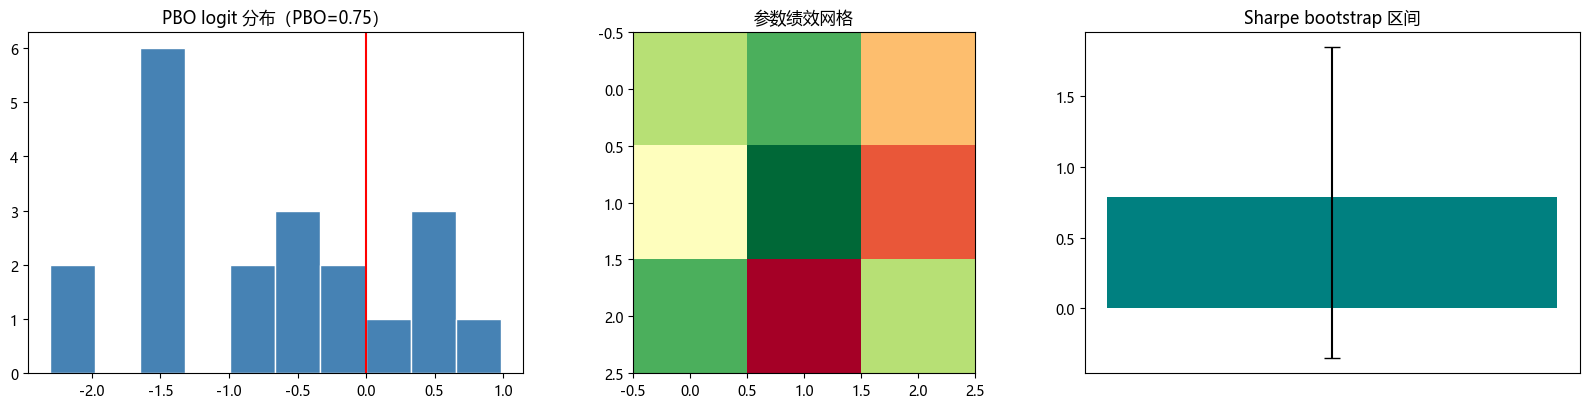

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].hist(pbo['logits'], bins=10, color='steelblue', edgecolor='white')
ax[0].axvline(0, color='red'); ax[0].set_title('PBO logit 分布（PBO=%.2f）' % pbo['PBO'])
ax[1].imshow(grid, cmap='RdYlGn'); ax[1].set_title('参数绩效网格')
ax[2].bar([0], [bs['sharpe']], yerr=[[bs['sharpe']-bs['ci_low']], [bs['ci_high']-bs['sharpe']]],
          capsize=6, color='teal'); ax[2].set_title('Sharpe bootstrap 区间'); ax[2].set_xticks([])
plt.tight_layout(); plt.show()

## 五、面试要点

- **PBO 高意味着什么？** 样本内最优策略在样本外大概率落到下半区，回测结果不可信，常见于参数/策略选择过多而样本有限。
- **Deflated Sharpe 校正了什么？** 多次试验后最大 Sharpe 的选择偏差；只有显著高于「运气基准 SR0」的 Sharpe 才算真本事。
- **为什么要做置换检验？** 若打乱信号后策略仍能盈利，说明收益可能来自其他来源而非信号；p 值低才支持信号有效。
- **如何降低过拟合？** 减少自由参数、样本外/walk-forward、用经济逻辑约束、报告全部试验而非只报最优、足够长的样本。

## 六、练习

1. 增加策略数量，观察 PBO 与 SR0 如何上升。
2. 用真实因子策略收益替代随机股票，重算 PBO。
3. 改变 CSCV 分块数，检验 PBO 稳定性。
4. 推导多重检验下期望最大 Sharpe 的近似公式。